# Respiratory Illness Hospitalizations Across Demographic Groups in Washington State
Chris McCarthy

DSC 680 

Project 1, Milestone 3

**Business problem.** COVID-19, influenza and RSV put Washington residents in the hospital every year. Knowing which demographic groups are hospitalized most often can help public health organizations decide where to focus outreach, vaccination and access to care.

**Research questions**
1. Which race and ethnicity groups have the highest hospitalization rates for COVID-19, influenza and RSV?
2. Which age groups have the highest hospitalization rates for each illness?
3. Are these differences consistent across the 2024-25 and 2025-26 seasons and across the three illnesses?

**Data source:** Washington State Department of Health (DOH) Respiratory Illness Data Dashboard, downloadable CSV files.

**Notebook outline**
1. Setup and data loading
2. Data exploration
3. Data preparation
4. Exploratory data analysis and visualization
5. Linear regression analysis of differences by race
6. Summary of findings

## 1. Setup and loading the data

I use pandas and NumPy to prepare the data, Matplotlib and Seaborn for charts, and scikit-learn for the model.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

In [2]:
#chart settings used throughout the notebook
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

#one color per illness, used in every chart
ILLNESS_COLORS = {"COVID-19": "#2a78d6", "Influenza": "#eb6834", "RSV": "#1baf7a"}
ILLNESSES = list(ILLNESS_COLORS)

#folder for the charts used in the white paper
os.makedirs("figures", exist_ok=True)

In [3]:
#file names as downloaded from the DOH dashboard
HOSP_FILE = "data/respiratory_hospitalizations_downloadable.csv"
DEATH_FILE = "data/respiratory_deaths_downloadable.csv"
DICT_FILE = "data/data_dictionary_respiratory_surveillance.csv"

hospitalizations_raw = pd.read_csv(HOSP_FILE)
deaths_raw = pd.read_csv(DEATH_FILE)
data_dictionary = pd.read_csv(DICT_FILE)

print("Hospitalization rows:", hospitalizations_raw.shape)
print("Death rows:", deaths_raw.shape)

Hospitalization rows: (58644, 11)
Death rows: (106, 11)


## 2. Understanding the data

The DOH data dictionary defines each column. I also used it as the starting point for the data dictionary in the white paper appendix.

In [4]:
pd.set_option("display.max_colwidth", 120)
data_dictionary

,Variable Name,Definition
0,Condition,"Respiratory condition (e.g., COVID-19, Influenza, or RSV)."
1,Location,"Geographic location (i.e., Statewide)."
2,Season,The respiratory season year range; with the season starting the first week of October (week 40) and ending in the la...
3,Week Start,The start of the week date; with Sunday as the start day.
4,Week End,The end of the week date; with Saturday as the end day.
5,Week,The MMWR week within the respiratory season; with the first week of October as the start week of the season (week 40...
6,Demographic Category,"The demographic category (i.e., overall, age, sex, race, or ethnicity)."
7,Demographic,"The specific demographic (e.g., specific age, sex, race, or ethnicity group)."
8,Metric,"The reported metric (e.g., counts, percentages, or rates)."
9,Values,The metric value.


In [5]:
hospitalizations_raw.head()

,Condition,Location,Season,Week Start,Week End,Week,Demographic Category,Demographic,Metric,Values,Date Updated
0,Combined conditions,Benton County,2024-2025,2024-09-29,2024-10-05,40,Overall,All,"4-Week Hospitalization Rate Per 100,000 People for Combined Conditions",NaN,2026-10-13 16:27:30 PM
1,Combined conditions,Benton County,2024-2025,2024-09-29,2024-10-05,40,Overall,All,4-Week Hospitalization Rate Lower Confidence Level for Combined Conditions,NaN,2026-10-13 16:27:30 PM
2,Combined conditions,Benton County,2024-2025,2024-09-29,2024-10-05,40,Overall,All,4-Week Hospitalization Rate Upper Confidence Level for Combined Conditions,NaN,2026-10-13 16:27:30 PM
3,Combined conditions,Benton County,2024-2025,2024-10-06,2024-10-12,41,Overall,All,"4-Week Hospitalization Rate Per 100,000 People for Combined Conditions",NaN,2026-10-13 16:27:30 PM
4,Combined conditions,Benton County,2024-2025,2024-10-06,2024-10-12,41,Overall,All,4-Week Hospitalization Rate Lower Confidence Level for Combined Conditions,NaN,2026-10-13 16:27:30 PM


The hospitalization file is in long format: each row holds one value for one illness, location, week, demographic group and metric. The next cell lists the categories and metrics.

In [6]:
for col in ["Condition", "Location", "Season", "Demographic Category"]:
    print(col, "->", sorted(hospitalizations_raw[col].unique()), "\n")

print("Metrics:")
for m in hospitalizations_raw["Metric"].unique():
    print("  ", m)

Condition -> ['COVID-19', 'Combined conditions', 'Influenza', 'RSV'] 

Location -> ['Benton County', 'Clark County', 'Franklin County', 'King County', 'Pierce County', 'RESP-NET Counties', 'Snohomish County', 'Spokane County', 'Yakima County'] 

Season -> ['2024-2025', '2025-2026', '2026-2027', 'Last 12 Months'] 

Demographic Category -> ['Age', 'Ethnicity', 'Overall', 'Race', 'Sex'] 

Metrics:
   4-Week Hospitalization Rate Per 100,000 People for Combined Conditions
   4-Week Hospitalization Rate Lower Confidence Level for Combined Conditions
   4-Week Hospitalization Rate Upper Confidence Level for Combined Conditions
   4-Week Hospitalization Rate Per 100,000 People for COVID-19
   4-Week Hospitalization Rate Lower Confidence Level for COVID-19
   4-Week Hospitalization Rate Upper Confidence Level for COVID-19
   4-Week Hospitalization Rate Per 100,000 People for Influenza
   4-Week Hospitalization Rate Lower Confidence Level for Influenza
   4-Week Hospitalization Rate Upper Confid

The file has hospitalization rates per 100,000 residents, plus lower and upper confidence limits. Each rate covers a rolling four-week period. Rates per 100,000 account for differences in population size, but not necessarily for differences in age.

The "Last 12 Months" category repeats weeks that are already in the regular seasons, and the 2026-2027 season is incomplete. The crosstab below shows which locations have demographic data.

In [7]:
pd.crosstab(hospitalizations_raw["Location"], hospitalizations_raw["Demographic Category"])

Demographic Category,Age,Ethnicity,Overall,Race,Sex
Location,,,,,
Benton County,0,0,1428,0,0
Clark County,0,0,1428,0,0
Franklin County,0,0,1428,0,0
King County,0,0,1428,0,0
Pierce County,0,0,1428,0,0
RESP-NET Counties,22896,3816,1428,13356,5724
Snohomish County,0,0,1428,0,0
Spokane County,0,0,1428,0,0
Yakima County,0,0,1428,0,0


Demographic breakdowns are only available for the combined RESP-NET Counties surveillance area; individual counties only report overall rates. So the demographic findings in this project describe the surveillance area, not Washington State as a whole.

## 3. Data preparation

Steps used to prepare the hospitalization data:
1. Keep only RESP-NET Counties.
2. Keep the 2024-2025 and 2025-2026 seasons and drop the overlapping or incomplete season categories.
3. Drop "Combined conditions" so each illness is analyzed on its own.
4. Split the metric column into separate rate, lower limit and upper limit columns.
5. Convert the week start column to a date and pull out the month.
6. Check for duplicate rows and missing values.

In [8]:
#steps 1-3: keep only the rows used in this project
hospitalizations = hospitalizations_raw.copy()
hospitalizations = hospitalizations[hospitalizations["Location"] == "RESP-NET Counties"]
hospitalizations = hospitalizations[hospitalizations["Season"].isin(["2024-2025", "2025-2026"])]
hospitalizations = hospitalizations[hospitalizations["Condition"] != "Combined conditions"]
print(hospitalizations.shape)

(23625, 11)


In [9]:
#step 4a: label each metric as rate, lower or upper
def metric_type(text):
    if "Lower" in text:
        return "lower"
    if "Upper" in text:
        return "upper"
    return "rate"

hospitalizations["metric_type"] = hospitalizations["Metric"].apply(metric_type)
hospitalizations["metric_type"].value_counts()

metric_type
rate     7875
lower    7875
upper    7875
Name: count, dtype: int64

In [10]:
#step 4b: reshape so rate, lower and upper sit side by side on one row
hospitalizations = hospitalizations.pivot_table(
    index=["Condition", "Season", "Week Start", "Demographic Category", "Demographic"],
    columns="metric_type",
    values="Values",
).reset_index()
hospitalizations.columns.name = None

In [11]:
#step 5: convert dates, add the month, and use shorter column names
hospitalizations["Week Start"] = pd.to_datetime(hospitalizations["Week Start"])
hospitalizations["month"] = hospitalizations["Week Start"].dt.month

hospitalizations = hospitalizations.rename(columns={
    "Condition": "illness",
    "Season": "season",
    "Week Start": "week_start",
    "Demographic Category": "category",
    "Demographic": "group",
})
print(hospitalizations.shape)
hospitalizations.head()

(6532, 9)


,illness,season,week_start,category,group,lower,rate,upper,month
0,COVID-19,2024-2025,2024-10-20,Age,Age 0-4,0.65,1.09,1.82,10
1,COVID-19,2024-2025,2024-10-20,Age,Age 1-4,0.26,0.58,1.26,10
2,COVID-19,2024-2025,2024-10-20,Age,Age 18-29,0.50,0.73,1.06,10
3,COVID-19,2024-2025,2024-10-20,Age,Age 18-49,0.66,0.81,1.00,10
4,COVID-19,2024-2025,2024-10-20,Age,Age 30-39,0.44,0.65,0.96,10


I check for missing rates in the filtered long-format data, before the reshape, because `pivot_table()` can drop rows where every metric is missing. The duplicate check looks for identical rows.

In [12]:
#step 6a: the filtered long-format rows, rates only
filtered_rates = hospitalizations_raw[
    (hospitalizations_raw["Location"] == "RESP-NET Counties")
    & (hospitalizations_raw["Season"].isin(["2024-2025", "2025-2026"]))
    & (hospitalizations_raw["Condition"] != "Combined conditions")
    & (hospitalizations_raw["Metric"].str.contains("Per 100,000"))
].copy()

print("Duplicate rows:", filtered_rates.duplicated().sum())
print("Missing rates overall: {:.1%}".format(filtered_rates["Values"].isna().mean()))

Duplicate rows: 0
Missing rates overall: 17.1%


In [13]:
#step 6b: which groups have the most missing rates?
filtered_rates["missing"] = filtered_rates["Values"].isna()
missing_rates = filtered_rates.groupby(["Demographic Category", "Demographic"])["missing"].mean()
missing_rates.sort_values(ascending=False).head(8)

Demographic Category  Demographic 
Sex                   Unknown sex     1.000000
Race                  Unknown race    1.000000
Age                   Age 18-29       0.098413
                      Age 1-4         0.098413
                      Age 30-39       0.098413
                      Age 40-49       0.098413
                      Age 5-17        0.098413
                      Age 18-49       0.098413
Name: missing, dtype: float64

Unknown race and unknown sex have no reported rates, which makes sense because there is no population count to divide by. The blanks at the start of each season come from the four-week reporting window, and the extra missing influenza rates fall in summer, when flu activity is low.

I leave missing rates out instead of filling them in, and I keep reported zero rates. Reporting coverage may differ between groups, which could affect comparisons.

In [14]:
hospitalizations = hospitalizations[~hospitalizations["group"].isin(["Unknown race", "Unknown sex"])]
hospitalizations = hospitalizations.dropna(subset=["rate"])
print("Clean rows:", hospitalizations.shape[0])
hospitalizations.groupby(["category", "illness"]).size().unstack()

Clean rows: 6532


illness,COVID-19,Influenza,RSV
category,,,
Age,1224,960,1224
Ethnicity,204,160,204
Overall,102,80,102
Race,612,480,612
Sex,204,160,204


Seasonal averages use the weekly rolling four-week rates that are available. Each average is the typical four-week hospitalization burden during the reported part of the season; it is not a cumulative seasonal rate. Because neighboring weeks overlap and coverage can differ, I treat these averages as descriptive.

In [15]:
#calculate the mean reported rate for each demographic group, illness and season.
season_averages = hospitalizations.groupby(["category", "group", "illness", "season"])["rate"].mean()
season_averages = season_averages.reset_index(name="avg_rate")
season_averages.head()

,category,group,illness,season,avg_rate
0,Age,Age 0-4,COVID-19,2024-2025,0.910408
1,Age,Age 0-4,COVID-19,2025-2026,0.434340
2,Age,Age 0-4,Influenza,2024-2025,2.697143
3,Age,Age 0-4,Influenza,2025-2026,1.409231
4,Age,Age 0-4,RSV,2024-2025,5.607959


## 4. Exploratory data analysis

### 4.1 Summary statistics

In [16]:
overall_rates = hospitalizations[hospitalizations["category"] == "Overall"]
overall_rates.groupby(["illness", "season"])["rate"].describe().round(2)

count  mean   std   min   25%   50%   75%   max
illness   season                                                    
COVID-19  2024-2025   49.0  1.55  0.57  0.99  1.19  1.37  1.60  3.14
          2025-2026   53.0  0.66  0.60  0.12  0.31  0.45  0.67  2.75
Influenza 2024-2025   28.0  3.57  3.18  0.14  0.78  2.56  5.82  9.83
          2025-2026   52.0  1.39  1.60  0.08  0.24  0.65  1.95  5.17
RSV       2024-2025   49.0  0.81  0.89  0.00  0.03  0.34  1.74  2.55
          2025-2026   53.0  0.65  0.70  0.02  0.05  0.24  1.28  2.14

### 4.2 Figure 1: hospitalization trends over time
The overall hospitalization rate for each illness, week by week, shows the seasonal pattern across both seasons.

In [17]:
#one column per illness. Weeks with no value stay blank (NaN),
# so the line shows a gap instead of connecting across unreported weeks.
weekly_trends = overall_rates.pivot_table(index="week_start", columns="illness", values="rate")
all_weeks = pd.date_range(weekly_trends.index.min(), weekly_trends.index.max(), freq="7D")
weekly_trends = weekly_trends.reindex(all_weeks)

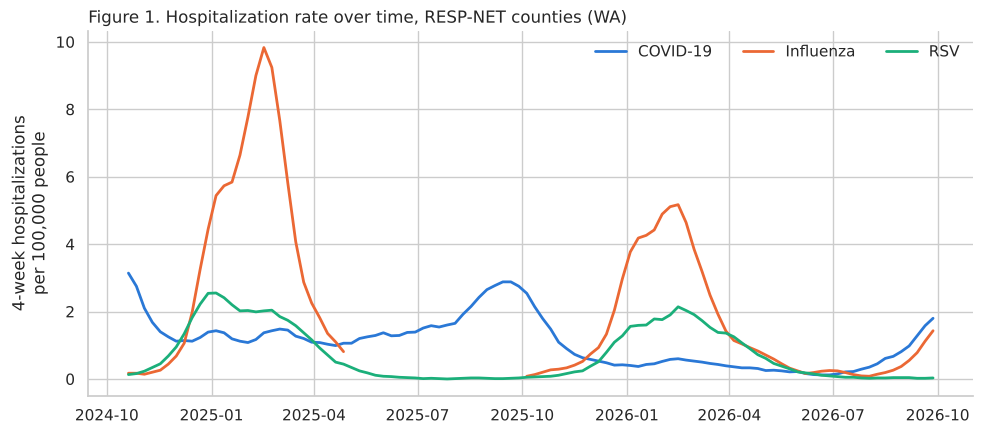

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for illness in ILLNESSES:
    ax.plot(weekly_trends.index, weekly_trends[illness], color=ILLNESS_COLORS[illness], lw=2, label=illness)

ax.set_title("Figure 1. Hospitalization rate over time, RESP-NET counties (WA)", loc="left")
ax.set_ylabel("4-week hospitalizations\nper 100,000 people")
ax.set_xlabel("")
ax.legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout()
plt.savefig("figures/fig1_trend_over_time.png", dpi=200)
plt.show()

Hospitalization rates rise in winter for all three illnesses, and COVID-19 also has waves outside winter. The gaps in the influenza line are weeks with no reported rate, not weeks with zero hospitalizations.

### 4.3 Figure 2: race and ethnicity (research question 1)
Average four-week hospitalization rates by race group for each illness. The dashed line is the overall rate for the surveillance area.

In [19]:
#average each race group over the two seasons
race_averages = season_averages[season_averages["category"] == "Race"]
race_two_seasons = race_averages.groupby(["group", "illness"])["avg_rate"].mean().reset_index()

#overall rate for each illness (the dashed line)
overall_seasons = season_averages[season_averages["category"] == "Overall"]
overall_average = overall_seasons.groupby("illness")["avg_rate"].mean()

#shorter labels for the charts
SHORT = {"American Indian Alaska Native": "AI/AN",
         "Native Hawaiian Pacific Islander": "NH/PI",
         "Multiple races": "Multiple"}
race_two_seasons["label"] = race_two_seasons["group"].replace(SHORT)
race_two_seasons.head()

,group,illness,avg_rate,label
0,American Indian Alaska Native,COVID-19,0.913481,AI/AN
1,American Indian Alaska Native,Influenza,2.544904,AI/AN
2,American Indian Alaska Native,RSV,0.622871,AI/AN
3,Asian,COVID-19,0.566452,Asian
4,Asian,Influenza,1.200288,Asian


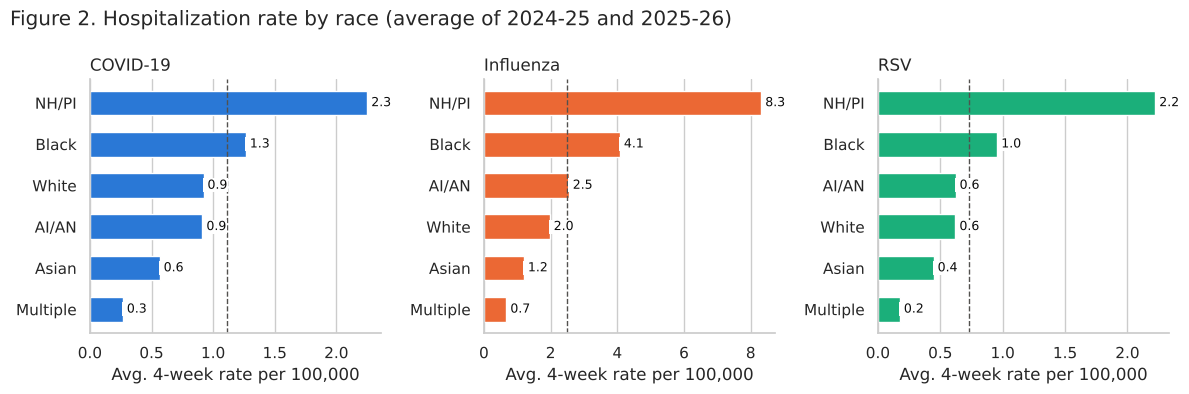

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=False)
for ax, illness in zip(axes, ILLNESSES):
    illness_data = race_two_seasons[race_two_seasons["illness"] == illness].sort_values("avg_rate")
    ax.barh(illness_data["label"], illness_data["avg_rate"], color=ILLNESS_COLORS[illness], height=0.6)
    ax.axvline(overall_average[illness], color="#52514e", ls="--", lw=1)

    
    for y, v in enumerate(illness_data["avg_rate"]):
        ax.text(v, y, f" {v:.1f}", va="center", fontsize=9, color="#0b0b0b",
                bbox=dict(facecolor="white", edgecolor="none", pad=0.5))

    ax.set_title(illness, loc="left")
    ax.set_xlabel("Avg. 4-week rate per 100,000")
    ax.grid(axis="y", visible=False)

fig.suptitle("Figure 2. Hospitalization rate by race (average of 2024-25 and 2025-26)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("figures/fig2_rate_by_race.png", dpi=200)
plt.show()

In [21]:
ethnicity_averages = season_averages[season_averages["category"] == "Ethnicity"]
ethnicity_averages.pivot_table(index="group", columns=["illness", "season"], values="avg_rate").round(2)

illness       COVID-19           Influenza                 RSV          
season       2024-2025 2025-2026 2024-2025 2025-2026 2024-2025 2025-2026
group                                                                   
Hispanic          1.02      0.46      2.34      1.06      0.62      0.46
Non-Hispanic      1.34      0.57      3.30      1.27      0.86      0.68

Native Hawaiian/Pacific Islander (NH/PI) residents have the highest average rates for all three illnesses, followed by Black residents. Asian and Multiple-race residents are among the groups with the lowest rates. Hispanic residents have lower rates than non-Hispanic residents.

The dataset doesn't say whether these rates are age-adjusted, so differences in age and other unmeasured factors may play a part. These comparisons don't test for statistical significance or causes.

### 4.4 Figure 3: age (research question 2)
I use the main age groups (0-4, 5-17, 18-49, 50-64 and 65+) so the groups don't overlap, and look at the more detailed groups separately.

In [22]:
AGE_ORDER = ["Age 0-4", "Age 5-17", "Age 18-49", "Age 50-64", "Age 65+"]

#Average each main age group over the two seasons
age_averages = season_averages[(season_averages["category"] == "Age") & (season_averages["group"].isin(AGE_ORDER))]
age_two_seasons = age_averages.groupby(["group", "illness"])["avg_rate"].mean().reset_index()

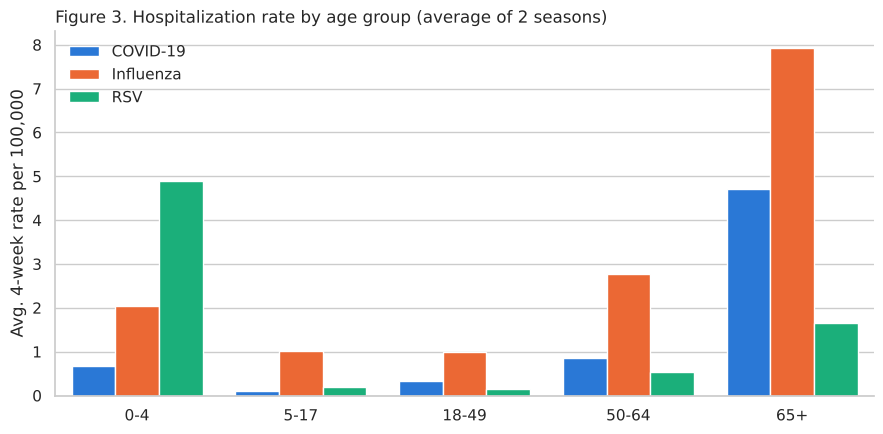

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=age_two_seasons, x="group", y="avg_rate", hue="illness",
            order=AGE_ORDER, hue_order=ILLNESSES, palette=ILLNESS_COLORS, saturation=1, ax=ax)
ax.set_title("Figure 3. Hospitalization rate by age group (average of 2 seasons)", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Avg. 4-week rate per 100,000")
ax.set_xticks(range(len(AGE_ORDER)), [g.replace("Age ", "") for g in AGE_ORDER])
ax.legend(title="", frameon=False)
plt.tight_layout()
plt.savefig("figures/fig3_rate_by_age.png", dpi=200)
plt.show()

In [24]:
#examine the more detailed age categories separately.
detailed_age_groups = ["Age <1", "Age 1-4", "Age 65-74", "Age 75+"]
detailed_age_rates = season_averages[season_averages["category"] == "Age"]
detailed_age_rates = detailed_age_rates[detailed_age_rates["group"].isin(detailed_age_groups)]
detailed_age_table = detailed_age_rates.pivot_table(index="group", columns="illness", values="avg_rate")
detailed_age_table.round(1)

illness,COVID-19,Influenza,RSV
group,,,
Age 1-4,0.3,1.8,3.4
Age 65-74,2.4,5.1,1.0
Age 75+,8.1,12.0,2.6
Age <1,2.1,3.2,11.1


Each illness has a different age pattern. Adults 65 and older, especially 75 and older, have the highest COVID-19 and influenza rates. For RSV, children under five have the highest rates, especially infants, and older adults are also elevated. These are descriptive comparisons; they don't isolate the effect of age.

### 4.5 Figure 4: relative hospitalization rates
I calculate rate ratios with White residents as the reference group. Each ratio divides a group's seasonal average by the White average for the same illness and season, so 2 means twice the rate and 1 means the same rate.

In [25]:
#White averages for each illness and season
reference_rates = race_averages[race_averages["group"] == "White"][["illness", "season", "avg_rate"]]
reference_rates = reference_rates.rename(columns={"avg_rate": "ref_rate"})

# divide each group's average by the White average
rate_ratios = race_averages.merge(reference_rates, on=["illness", "season"])
rate_ratios["rate_ratio"] = rate_ratios["avg_rate"] / rate_ratios["ref_rate"]
rate_ratios["label"] = rate_ratios["group"].replace(SHORT)
rate_ratios["column"] = rate_ratios["illness"] + "\n" + rate_ratios["season"]

In [26]:
#table for the heatmap: one row per group, sorted from highest to lowest average ratio
ratio_table = rate_ratios[rate_ratios["group"] != "White"].pivot_table(index="label", columns="column", values="rate_ratio")
ratio_table = ratio_table.loc[ratio_table.mean(axis=1).sort_values(ascending=False).index]
ratio_table.round(2)

column,COVID-19\n2024-2025,COVID-19\n2025-2026,Influenza\n2024-2025,Influenza\n2025-2026,RSV\n2024-2025,RSV\n2025-2026
label,,,,,,
NH/PI,2.32,2.72,4.02,4.74,3.58,3.57
Black,1.40,1.31,2.09,2.02,1.49,1.60
AI/AN,0.97,1.03,1.34,1.15,0.87,1.17
Asian,0.65,0.53,0.59,0.66,0.72,0.72
Multiple,0.29,0.30,0.35,0.33,0.24,0.34


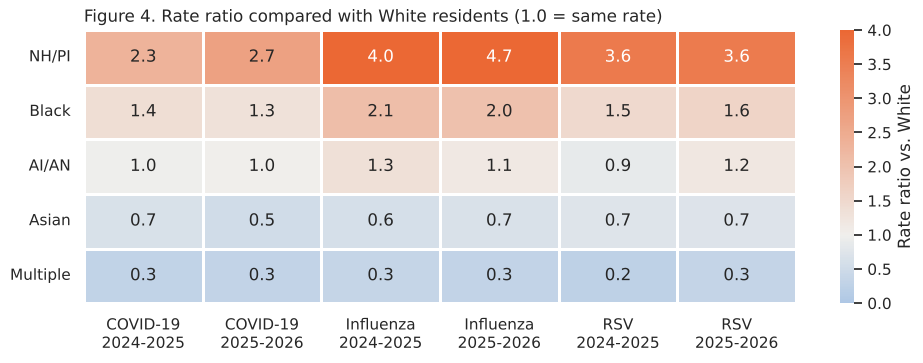

In [27]:
#blue = lower than White, gray = the same, orange = higher
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(ratio_table, annot=True, fmt=".1f", cmap=cmap, center=1, vmin=0, vmax=4,
            linewidths=2, linecolor="white", cbar_kws={"label": "Rate ratio vs. White"}, ax=ax)
ax.set_title("Figure 4. Rate ratio compared with White residents (1.0 = same rate)", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig("figures/fig4_rate_ratio_heatmap.png", dpi=200)
plt.show()

### 4.6 Figure 5: consistency across seasons (research question 3)
Each point is one race group for one illness. Points on the reference line have the same rate ratio in both seasons. This checks whether the relative rates look similar from season to season; it isn't a formal significance test.

In [28]:
#one row per group and illness, with a column for each season's ratio
season_comparison = rate_ratios[rate_ratios["group"] != "White"].pivot_table(
    index=["label", "illness"], columns="season", values="rate_ratio").reset_index()

print("Correlation of ratios between seasons: {:.2f}".format(
    season_comparison["2024-2025"].corr(season_comparison["2025-2026"])))

Correlation of ratios between seasons: 0.99


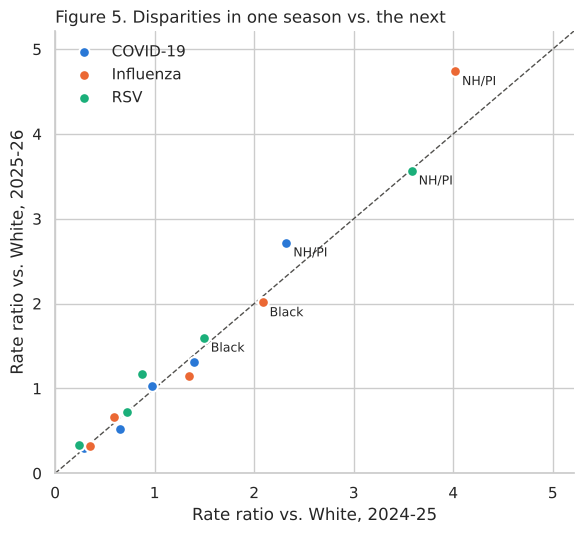

In [29]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for illness in ILLNESSES:
    illness_data = season_comparison[season_comparison["illness"] == illness]
    ax.scatter(illness_data["2024-2025"], illness_data["2025-2026"], s=60, color=ILLNESS_COLORS[illness],
               edgecolor="white", lw=1.5, label=illness, zorder=3)

#reference line: same ratio in both seasons
axis_limits = [0, max(season_comparison[["2024-2025", "2025-2026"]].max()) * 1.1]
ax.plot(axis_limits, axis_limits, color="#52514e", ls="--", lw=1, zorder=1)
ax.set_xlim(axis_limits)
ax.set_ylim(axis_limits)

#label only the higher ratios so the chart stays readable
for _, observation in season_comparison[season_comparison["2024-2025"] > 1.4].iterrows():
    ax.annotate(observation["label"], (observation["2024-2025"], observation["2025-2026"]),
                xytext=(5, -10), textcoords="offset points", fontsize=9)

ax.set_xlabel("Rate ratio vs. White, 2024-25")
ax.set_ylabel("Rate ratio vs. White, 2025-26")
ax.set_title("Figure 5. Disparities in one season vs. the next", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("figures/fig5_season_consistency.png", dpi=200)
plt.show()

The points sit close to the reference line, so the relative rates were similar in both seasons. Overall rates fell in 2025-26, especially for COVID-19, while the gaps between groups stayed about the same. The correlation is based on a small number of group and illness combinations, and it doesn't show that the pattern will hold in future seasons.

### 4.7 Reliability of weekly estimates: confidence intervals
DOH provides 95% confidence limits for each weekly rate. I divide the width of the interval (upper minus lower) by the rate to get a relative width; bigger values mean more uncertainty. Zero rates are left out of this calculation.

In [30]:
race_intervals = hospitalizations[(hospitalizations["category"] == "Race") & (hospitalizations["rate"] > 0)].copy()
race_intervals["relative_ci_width"] = (race_intervals["upper"] - race_intervals["lower"]) / race_intervals["rate"]
interval_summary = race_intervals.groupby(["group", "illness"])["relative_ci_width"].median()
interval_summary = interval_summary.unstack().round(1)
interval_summary.sort_values("COVID-19", ascending=False)

illness,COVID-19,Influenza,RSV
group,,,
American Indian Alaska Native,3.0,2.0,2.5
Multiple races,3.0,2.3,3.3
Native Hawaiian Pacific Islander,2.9,2.0,1.9
Black,1.2,1.0,1.4
Asian,1.1,1.0,1.5
White,0.3,0.4,0.6


Several of the smaller groups have much wider intervals, so single weekly estimates for them should be read with caution. Seasonal averages give a broader summary, though I didn't calculate confidence intervals for the averages themselves.

### 4.8 Additional context: deaths
The deaths file has no demographic breakdowns, so I use it only for context on each season.

In [31]:
season_deaths = deaths_raw[deaths_raw["Metric"].str.startswith("Season Total Deaths")]
season_deaths.pivot_table(index="Condition", columns="Season", values="Values", aggfunc="max")

Season,2024-2025,2025-2026
Condition,,
COVID-19,556,120
Influenza,508,271
RSV,101,81


The 2025-26 death totals are incomplete. The DOH dashboard notes that COVID-19 and RSV death data run only through July 18, 2026, while the season continues into late September. Reported COVID-19 deaths drop from 556 to 120, but with the missing weeks the data can't show how large the real decline was, so I don't treat the change in deaths as a finding.

## 5. Linear regression analysis

The charts show differences in hospitalization rates between race groups, but rates also change with the illness, month and season. I fit two linear regression models to see whether adding race improves the model after accounting for those.

**Model setup**
- The target is the natural log of the rolling four-week hospitalization rate. The log keeps a few very high weeks from dominating.
- I add 0.1 before taking the log so reported zero rates stay in. Dropping zeros would change which rows are in the model, mostly for the smaller groups. The sensitivity analysis tests this choice.
- Illness, season, month and race become dummy (0/1) columns, with White residents as the reference group for race.
- I compare R² for a baseline model (illness, season and month) and a full model (baseline plus race) using five-fold cross-validation with shuffled rows. R² is measured on the log scale. Because reporting windows overlap, the folds aren't fully independent.

If R² goes up, race adds predictive information in this dataset; that alone doesn't show that race causes the difference.

I considered Poisson regression, but the dataset has rates, not raw counts. I also considered a random forest. I chose linear regression because it's easy to interpret and fits the exploratory scope of this project.

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

#race rows only, with the log of (rate + 0.1) as the target
model_data = hospitalizations[hospitalizations["category"] == "Race"].copy()
model_data["log_rate"] = np.log(model_data["rate"] + 0.1)

print("Rows used:", len(model_data))
print("Share of weeks with a rate of 0, by group:")
print((model_data["rate"] == 0).groupby(model_data["group"]).mean().round(2))

Rows used: 1704
Share of weeks with a rate of 0, by group:
group
American Indian Alaska Native       0.27
Asian                               0.07
Black                               0.07
Multiple races                      0.30
Native Hawaiian Pacific Islander    0.19
White                               0.03
Name: rate, dtype: float64


In [33]:
#turn the categories into 0/1 columns
X_baseline = pd.get_dummies(model_data[["illness", "season", "month"]].astype(str), drop_first=True)
race_dummies = pd.get_dummies(model_data["group"]).drop(columns="White")   # White = reference group
X_full = pd.concat([X_baseline, race_dummies], axis=1)
y = model_data["log_rate"]

In [34]:
#five-fold cross-validation for both models
cv = KFold(n_splits=5, shuffle=True, random_state=42)
baseline_scores = cross_val_score(LinearRegression(), X_baseline, y, cv=cv, scoring="r2")
full_scores = cross_val_score(LinearRegression(), X_full, y, cv=cv, scoring="r2")

print("Baseline R² (month + illness + season): {:.2f} ± {:.2f}".format(baseline_scores.mean(), baseline_scores.std()))
print("Full R²     (+ race):                   {:.2f} ± {:.2f}".format(full_scores.mean(), full_scores.std()))

Baseline R² (month + illness + season): 0.36 ± 0.04
Full R²     (+ race):                   0.52 ± 0.06


Next I fit the full model on all rows. Taking exp() of each race coefficient gives a multiplier compared with White residents on the shifted scale (rate + 0.1). These are ratios of modeled geometric means, so they won't exactly match the ratios of average rates in Figure 4.

In [35]:
full_model = LinearRegression()
full_model.fit(X_full, y)
coefficients = pd.Series(full_model.coef_, index=X_full.columns)
race_coefficients = coefficients[race_dummies.columns]
model_ratios = np.exp(race_coefficients)
model_ratios = model_ratios.rename("modeled ratio of rate + 0.1 vs. White")
model_ratios = model_ratios.sort_values(ascending=False).round(2)
model_ratios

Native Hawaiian Pacific Islander    2.09
Black                               1.40
American Indian Alaska Native       0.87
Asian                               0.74
Multiple races                      0.41
Name: modeled ratio of rate + 0.1 vs. White, dtype: float64

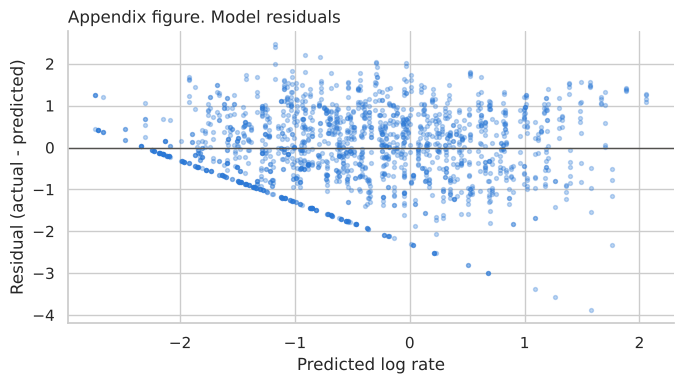

In [36]:
#examine in-sample residuals for systematic patterns.
predicted_rates = full_model.predict(X_full)
residuals = y - predicted_rates

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(predicted_rates, residuals, s=8, alpha=0.3, color="#2a78d6")
ax.axhline(0, color="#52514e", lw=1)
ax.set_xlabel("Predicted log rate")
ax.set_ylabel("Residual (actual - predicted)")
ax.set_title("Appendix figure. Model residuals", loc="left")
plt.tight_layout()
plt.savefig("figures/appendix_residuals.png", dpi=200)
plt.show()

The residual plot shows the in-sample prediction errors. The diagonal line of points in the lower part of the plot is the reported zero rates: they all become log(0.1), about -2.3, so their residuals line up. That comes from the transformation and shows the model doesn't handle zero weeks well. The plot alone doesn't confirm the regression assumptions.

### Sensitivity analysis
I refit the regression two other ways, once dropping the zero rates and once adding 0.05 instead of 0.1, and compare the results with the original model. This shows how much the race estimates depend on how zeros are handled.

In [37]:
def race_ratios(data):
    """Fit the full model on data["y"] and return exp(race coefficients) vs. White."""
    baseline_features = pd.get_dummies(data[["illness", "season", "month"]].astype(str), drop_first=True)
    race_features = pd.get_dummies(data["group"]).drop(columns="White")
    X = pd.concat([baseline_features, race_features], axis=1)

    model = LinearRegression()
    model.fit(X, data["y"])
    coefficients = pd.Series(model.coef_, index=X.columns)
    return np.exp(coefficients[race_features.columns])

In [38]:
race_rows = hospitalizations[hospitalizations["category"] == "Race"]

#version 1: drop the zero rates
positive_rates = race_rows[race_rows["rate"] > 0].copy()
positive_rates["y"] = np.log(positive_rates["rate"])

#version 2: add 0.05 instead of 0.1
small_offset_rates = race_rows.copy()
small_offset_rates["y"] = np.log(small_offset_rates["rate"] + 0.05)

#original: add 0.1
original_offset_rates = race_rows.copy()
original_offset_rates["y"] = np.log(original_offset_rates["rate"] + 0.1)

sensitivity = pd.DataFrame({
    "drop zero weeks": race_ratios(positive_rates),
    "log(rate + 0.05)": race_ratios(small_offset_rates),
    "log(rate + 0.1)  [used]": race_ratios(original_offset_rates),
}).round(2)
sensitivity.sort_values("log(rate + 0.1)  [used]", ascending=False)

,drop zero weeks,log(rate + 0.05),log(rate + 0.1) [used]
Native Hawaiian Pacific Islander,4.20,2.07,2.09
Black,1.75,1.44,1.40
American Indian Alaska Native,1.54,0.80,0.87
Asian,0.74,0.71,0.74
Multiple races,0.44,0.34,0.41


Adding race raises the cross-validated R² compared with the baseline model. The model's estimates follow the same pattern as Figure 4: higher for NH/PI and Black residents and lower for Asian and Multiple-race residents.

The AI/AN estimate moves from below to above the White reference depending on how zeros are handled, and the size of the NH/PI estimate changes too. So these estimates depend on preprocessing choices; this check doesn't test statistical significance.

The model has no interaction terms, so it assumes each race group's difference is the same for every illness and month. Neighboring rows share weeks, so shuffled cross-validation may overstate performance, and I haven't measured by how much. The model doesn't show causation or the statistical significance of individual race coefficients.

## 6. Summary of findings

| Research question | Findings |
|---|---|
| 1. Which race and ethnicity groups have the highest rates? | NH/PI and Black residents have the highest average rates across the three illnesses. Asian and Multiple-race residents have comparatively low rates. Hispanic residents have lower rates than non-Hispanic residents. |
| 2. Which age groups have the highest rates? | Adults 65 and older, especially 75 and older, have the highest COVID-19 and influenza rates. Children under five, especially infants, have the highest RSV rates. |
| 3. Are the differences consistent? | Relative rates are similar across the two seasons. Adding race improves the cross-validated R², though overlapping reporting windows limit how much that score can be trusted. |

These findings describe differences in reported hospitalization burden within the RESP-NET Counties. They can help guide further investigation and public health planning, but they shouldn't be applied to the whole state without more evidence. It isn't confirmed that the rates are age-adjusted beyond the disclaimer on the dashboard, reporting coverage may differ between groups, and the analysis doesn't determine the causes or statistical significance of the differences.